# 03 — Markov chain on daily AQI categories

**Part:** Member B — Markov chain (estimation, multi-step behaviour, long-run shares, spell lengths,
first-passage times, order test, out-of-sample check)

**Question.** *Given today's air quality, how likely is each category tomorrow and over the next days, how long
do bad spells last, how long until the next Severe day, and is one day of memory enough?*

## Mathematical formulation

| Item | Choice |
|---|---|
| Time parameter | discrete, $n = 0, 1, 2, \dots$ days |
| State space | $S = \{1,\dots,5\}$ = {Good/Satisfactory, Moderate, Poor, Very Poor, Severe} (CPCB classes of daily PM2.5; Good and Satisfactory merged because Good is rare in winter and both are "acceptable") |
| Random variables | $X_n$ = AQI state on day $n$; sojourn (spell) lengths $D_i$; first-passage time to Severe $T_S = \min\{n \ge 1: X_n = 5\}$ |
| Missing days | the chain is broken at a missing day: a transition $X_{n-1} \to X_n$ is used only if both days are valid |

**Model.** $\{X_n\}$ is a time-homogeneous first-order Markov chain:
$P(X_{n+1}=j \mid X_n=i, X_{n-1},\dots,X_0) = P(X_{n+1}=j \mid X_n=i) = p_{ij}$.

**Estimation.** With $n_{ij}$ = number of observed $i \to j$ transitions and $n_i = \sum_j n_{ij}$, the likelihood is
$\prod_{i,j} p_{ij}^{\,n_{ij}}$, which gives the MLE $\hat p_{ij} = n_{ij}/n_i$ (Anderson & Goodman 1957), with
standard error $\sqrt{\hat p_{ij}(1-\hat p_{ij})/n_i}$.

**Consequences used below.**
* $n$-step probabilities (Chapman–Kolmogorov): $P^{(n)} = P^n$.
* Stationary distribution: $\pi = \pi P$, $\sum_j \pi_j = 1$. The chain is irreducible and aperiodic, so
  $p^{(n)}_{ij} \to \pi_j$, and $\pi_j$ is the long-run share of days in state $j$.
* Spell length in state $i$: $D \sim$ Geometric$(1-p_{ii})$, $E[D] = 1/(1-p_{ii})$.
* Mean first-passage time to Severe: $m_i = 1 + \sum_{j \ne 5} p_{ij} m_j$, i.e. $m = (I - Q)^{-1}\mathbf 1$ where $Q$
  is $P$ without the Severe row and column; mean recurrence time $1/\pi_5$.
* Order test: under a first-order chain, $P(X_n=k \mid X_{n-1}=j, X_{n-2}=i)$ does not depend on $i$. The
  likelihood-ratio statistic $G^2 = 2\sum_{ijk} n_{ijk}\log(\hat p_{ijk}/\hat p_{jk})$ is $\chi^2$ with
  $\sum_j (r_j-1)(c_j-1)$ degrees of freedom ($r_j, c_j$ = non-empty rows/columns of the table for middle state $j$).

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

CLEAN = Path("../data/clean")
FIG = Path("../figures")
RES = Path("../results")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

STATES = ["Good/Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
SHORT = ["G/S", "Mod", "Poor", "VPoor", "Severe"]
CODE = {"Good": 0, "Satisfactory": 0, "Moderate": 1, "Poor": 2, "Very Poor": 3, "Severe": 4}
K = len(STATES)
SEV = 4
TRAIN_END = "2022-12-31"
SEASONS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
SEASON_OF = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
             6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}
COLORS = ["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#9d0208"]
RESULTS = {"states": STATES}

df = pd.read_csv(CLEAN / "delhi_rkpuram_daily.csv", parse_dates=["date"], index_col="date")
df["x"] = df.aqi_category.map(CODE)          # NaN on missing days
df["prev"] = df.x.shift(1)                   # state yesterday (NaN if yesterday was missing)
df["prev2"] = df.x.shift(2)                  # state the day before yesterday
assert (df.index.to_series().diff().dropna() == pd.Timedelta("1D")).all()  # daily grid, so shift = previous day
study = df[df.period == "study"].copy()
holdout = df[df.period == "holdout"].copy()
print(f"study: {study.index.min().date()} -> {study.index.max().date()}, valid days = {study.x.notna().sum()}, "
      f"usable transitions = {study[['prev', 'x']].notna().all(axis=1).sum()}")
study.x.value_counts().sort_index().rename(index=dict(enumerate(STATES))).to_frame("days")

study: 2016-01-01 -> 2025-12-31, valid days = 3430, usable transitions = 3394


,days
x,
Good/Satisfactory,1199
Moderate,620
Poor,425
Very Poor,886
Severe,300


### Helper functions

In [2]:
def transition_counts(d):
    """n_ij: transitions yesterday -> today where both days are valid."""
    t = d.dropna(subset=["prev", "x"])
    C = np.zeros((K, K))
    np.add.at(C, (t.prev.astype(int), t.x.astype(int)), 1)
    return C


def triple_counts(d):
    """n_ijk: (day before yesterday, yesterday, today), all three valid."""
    t = d.dropna(subset=["prev2", "prev", "x"])
    N = np.zeros((K, K, K))
    np.add.at(N, (t.prev2.astype(int), t.prev.astype(int), t.x.astype(int)), 1)
    return N


def row_normalise(C):
    """MLE p_ij = n_ij / n_i (rows with no data stay 0)."""
    n = C.sum(axis=1, keepdims=True)
    return np.divide(C, n, out=np.zeros_like(C), where=n > 0)


def stationary(P):
    """Left eigenvector of P for eigenvalue 1, normalised to sum 1."""
    w, v = np.linalg.eig(P.T)
    pi = np.real(v[:, np.argmin(np.abs(w - 1))])
    return pi / pi.sum()


def hitting_times(P, target=SEV):
    """Mean first-passage time to `target` from every other state: m = (I - Q)^-1 1."""
    keep = [i for i in range(len(P)) if i != target]
    Q = P[np.ix_(keep, keep)]
    m = np.linalg.solve(np.eye(len(keep)) - Q, np.ones(len(keep)))
    return dict(zip(keep, m))


def g2_independence(T):
    """Likelihood-ratio G^2 for independence of rows and columns in a contingency table, df adjusted
    for empty rows/columns."""
    r, c, n = T.sum(1), T.sum(0), T.sum()
    if n == 0:
        return 0.0, 0
    E = np.outer(r, c) / n
    m = T > 0
    return float(2 * np.sum(T[m] * np.log(T[m] / E[m]))), int(max((r > 0).sum() - 1, 0) * max((c > 0).sum() - 1, 0))


def g2_order(N3):
    """Anderson-Goodman test of first order (H0) against second order: for each middle state j,
    is today's state independent of the day before yesterday?"""
    G = dof = 0
    for j in range(K):
        g, d_ = g2_independence(N3[:, j, :])
        G, dof = G + g, dof + d_
    return G, dof, float(stats.chi2.sf(G, dof))


def run_lengths(x, state):
    """Lengths of maximal runs of `state` in a daily series; a missing day (NaN) ends a run."""
    hit = np.r_[False, x == state, False]
    d = np.diff(hit.astype(int))
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)


def show_matrix(P, title=""):
    if title:
        print(title)
    display(pd.DataFrame(P, index=[f"from {s}" for s in SHORT], columns=SHORT).round(3))

## 1. Transition matrix, 2016–2025

transition counts n_ij


,G/S,Mod,Poor,VPoor,Severe,total
from G/S,1024,149,11,1,1,1186
from Mod,140,317,122,33,1,613
from Poor,16,107,188,110,1,422
from VPoor,6,40,93,630,106,875
from Severe,0,1,7,102,188,298


estimated transition probabilities p_ij


,G/S,Mod,Poor,VPoor,Severe
from G/S,0.863,0.126,0.009,0.001,0.001
from Mod,0.228,0.517,0.199,0.054,0.002
from Poor,0.038,0.254,0.445,0.261,0.002
from VPoor,0.007,0.046,0.106,0.720,0.121
from Severe,0.000,0.003,0.023,0.342,0.631


largest standard error of any p_ij: 0.028


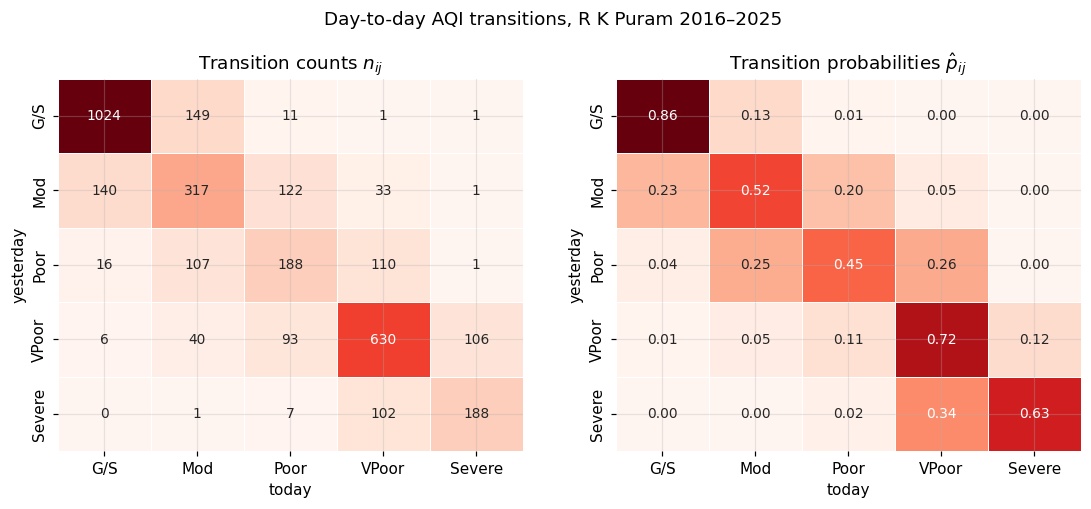

In [3]:
C = transition_counts(study)
P = row_normalise(C)
n_i = C.sum(axis=1)
SE = np.sqrt(P * (1 - P) / n_i[:, None])
print("transition counts n_ij")
display(pd.DataFrame(C.astype(int), index=[f"from {s}" for s in SHORT], columns=SHORT).assign(total=n_i.astype(int)))
show_matrix(P, "estimated transition probabilities p_ij")
print(f"largest standard error of any p_ij: {SE.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, M, fmt, ttl in [(axes[0], C, ".0f", "Transition counts $n_{ij}$"),
                        (axes[1], P, ".2f", r"Transition probabilities $\hat p_{ij}$")]:
    sns.heatmap(M, annot=True, fmt=fmt, cmap="Reds", cbar=False, ax=ax, xticklabels=SHORT, yticklabels=SHORT,
                annot_kws={"fontsize": 9}, linewidths=0.5, linecolor="white")
    ax.set(title=ttl, xlabel="today", ylabel="yesterday")
fig.suptitle("Day-to-day AQI transitions, R K Puram 2016–2025", y=1.02)
fig.savefig(FIG / "B01_transition_matrix.png")
plt.show()
RESULTS["counts"] = C.astype(int).tolist()
RESULTS["P"] = P.tolist()
RESULTS["P_se"] = SE.tolist()

### Check against the Poisson part: P(Severe tomorrow | Severe today)

Member A estimated $\hat q = 1 - 1/\bar L = 0.627$ from the mean episode length. Here the same quantity is the
diagonal entry $\hat p_{55} = n_{55}/n_5$. The two estimators differ only in how an episode that ends at a missing
day is handled (A counts it as ended, the chain drops that transition).

In [4]:
A_q = json.loads((RES / "poisson_params.json").read_text())["episode_continue_prob_q"]
n_ss, n_s = int(C[SEV, SEV]), int(n_i[SEV])
p_ss = n_ss / n_s
lo, hi = proportion_confint(n_ss, n_s, method="wilson")
bt = stats.binomtest(n_ss, n_s, A_q)
print(f"p_SS = {n_ss}/{n_s} = {p_ss:.3f}   95% Wilson CI [{lo:.3f}, {hi:.3f}]")
print(f"Member A q_hat = {A_q:.3f};  binomial test of p_SS = q_hat: p = {bt.pvalue:.2f}")
print(f"implied mean Severe spell 1/(1 - p_SS) = {1 / (1 - p_ss):.2f} days (A: mean episode length 2.68)")
RESULTS["p_SS"] = {"n_SS": n_ss, "n_S": n_s, "p": p_ss, "ci": [lo, hi], "memberA_q": A_q, "binom_p": bt.pvalue}

p_SS = 188/298 = 0.631   95% Wilson CI [0.575, 0.684]
Member A q_hat = 0.627;  binomial test of p_SS = q_hat: p = 0.90
implied mean Severe spell 1/(1 - p_SS) = 2.71 days (A: mean episode length 2.68)


**Reading.**
* The matrix is strongly **diagonal**: the most likely state tomorrow is today's state, except from Poor,
  which is a "transit" state between Moderate and Very Poor.
* Moves are almost always to a **neighbouring** class: the air gets worse or better one category at a time.
  Severe is entered almost only from Very Poor, and left almost only to Very Poor.
* $\hat p_{\text{Severe,Severe}} = 0.631$ (95 % CI 0.58–0.68) agrees with Member A's 0.627 from the episode
  analysis. The Poisson and Markov parts describe the same persistence.

## 2. Seasonal transition matrices

The year-round matrix mixes very different regimes. Transitions are split by the season of the arriving day
(IMD seasons as in the shared dataset: Winter = Dec–Feb, Summer = Mar–May, Monsoon = Jun–Sep, Post-monsoon = Oct–Nov).

transitions available per row (n_i) by season


,Winter,Summer,Monsoon,Post-monsoon
Good/Satisfactory,13,198,897,78
Moderate,71,283,199,60
Poor,101,216,31,74
Very Poor,482,128,10,255
Severe,184,3,0,111


Winter


,G/S,Mod,Poor,VPoor,Severe
from G/S,0.385,0.385,0.231,0.000,0.000
from Mod,0.099,0.451,0.268,0.183,0.000
from Poor,0.010,0.188,0.386,0.416,0.000
from VPoor,0.006,0.031,0.081,0.743,0.139
from Severe,0.000,0.005,0.011,0.359,0.625


Summer


,G/S,Mod,Poor,VPoor,Severe
from G/S,0.702,0.278,0.010,0.005,0.005
from Mod,0.173,0.512,0.265,0.046,0.004
from Poor,0.046,0.301,0.472,0.181,0.000
from VPoor,0.023,0.148,0.273,0.547,0.008
from Severe,0.000,0.000,0.333,0.667,0.000


Monsoon


,G/S,Mod,Poor,VPoor,Severe
from G/S,0.911,0.084,0.006,0.000,0.0
from Mod,0.377,0.538,0.065,0.020,0.0
from Poor,0.097,0.516,0.323,0.065,0.0
from VPoor,0.000,0.300,0.300,0.400,0.0
from Severe,0.000,0.000,0.000,0.000,0.0


Post-monsoon


,G/S,Mod,Poor,VPoor,Severe
from G/S,0.808,0.179,0.013,0.000,0.000
from Mod,0.150,0.550,0.250,0.050,0.000
from Poor,0.027,0.095,0.500,0.365,0.014
from VPoor,0.000,0.012,0.063,0.776,0.149
from Severe,0.000,0.000,0.036,0.306,0.658


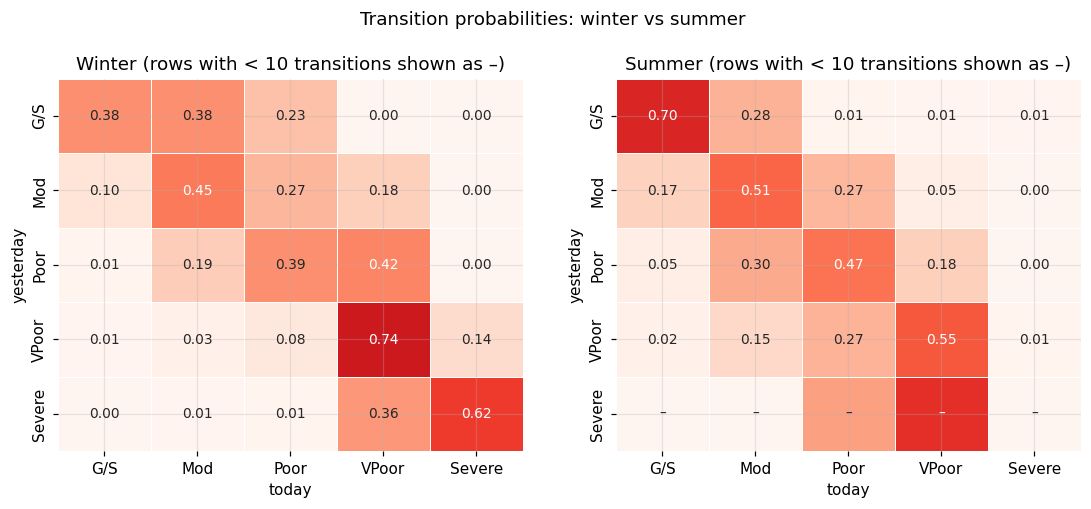

In [5]:
C_season = {s: transition_counts(study[study.season == s]) for s in SEASONS}
P_season = {s: row_normalise(C_season[s]) for s in SEASONS}
rows_n = pd.DataFrame({s: C_season[s].sum(axis=1).astype(int) for s in SEASONS}, index=STATES)
print("transitions available per row (n_i) by season")
display(rows_n)
for s in SEASONS:
    show_matrix(P_season[s], s)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, s in zip(axes, ["Winter", "Summer"]):
    annot = np.where(C_season[s].sum(axis=1, keepdims=True) >= 10,
                     np.vectorize("{:.2f}".format)(P_season[s]), "–")
    sns.heatmap(P_season[s], annot=annot, fmt="", cmap="Reds", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=SHORT, yticklabels=SHORT, linewidths=0.5, linecolor="white", annot_kws={"fontsize": 9})
    ax.set(title=f"{s} (rows with < 10 transitions shown as –)", xlabel="today", ylabel="yesterday")
fig.suptitle("Transition probabilities: winter vs summer", y=1.02)
fig.savefig(FIG / "B02_winter_vs_summer.png")
plt.show()
RESULTS["P_season"] = {s: P_season[s].tolist() for s in SEASONS}
RESULTS["n_season"] = {s: C_season[s].sum(axis=1).astype(int).tolist() for s in SEASONS}

### Is the chain the same in every season? (time-homogeneity test)
For each origin state $i$, a contingency table season × destination is tested for independence; the $G^2$
values and degrees of freedom are summed over $i$ (Anderson & Goodman 1957).

In [6]:
def homogeneity_test(groups):
    G = dof = 0
    for i in range(K):
        g, d_ = g2_independence(np.array([Cg[i] for Cg in groups]))
        G, dof = G + g, dof + d_
    return G, dof, float(stats.chi2.sf(G, dof))

hom_all = homogeneity_test([C_season[s] for s in SEASONS])
hom_ws = homogeneity_test([C_season["Winter"], C_season["Summer"]])
print(f"all four seasons equal:  G2 = {hom_all[0]:.1f}, df = {hom_all[1]}, p = {hom_all[2]:.1e}")
print(f"winter = summer:         G2 = {hom_ws[0]:.1f}, df = {hom_ws[1]}, p = {hom_ws[2]:.1e}")
for s in ["Winter", "Post-monsoon"]:
    lo_, hi_ = proportion_confint(C_season[s][SEV, SEV], C_season[s][SEV].sum(), method="wilson")
    print(f"{s:<13} p_SS = {P_season[s][SEV, SEV]:.3f}  [{lo_:.3f}, {hi_:.3f}]  (n = {int(C_season[s][SEV].sum())})")
RESULTS["homogeneity"] = {"all_seasons": hom_all, "winter_vs_summer": hom_ws}

all four seasons equal:  G2 = 347.4, df = 54, p = 1.8e-44
winter = summer:         G2 = 136.0, df = 18, p = 3.7e-20
Winter        p_SS = 0.625  [0.553, 0.692]  (n = 184)
Post-monsoon  p_SS = 0.658  [0.565, 0.739]  (n = 111)


**Reading.**
* The seasons are very different (homogeneity is rejected, p ≈ 10⁻⁴⁴). In **winter** the chain lives in
  Very Poor/Severe: from Very Poor, 74 % stay and 14 % become Severe; from Poor, 42 % worsen to Very Poor.
  In **summer** the same rows drift *down*: from Very Poor only 55 % stay and 44 % improve.
* The Severe row is estimated well only in winter and post-monsoon (184 and 111 transitions). Summer has only
  3 Severe days and the monsoon none, so those rows are not usable; the winter Good/Satisfactory row (13
  transitions) is also uncertain.
* Persistence of Severe is the **same** in winter and post-monsoon ($p_{SS}$ = 0.63 vs 0.66). What changes
  between seasons is how easily the chain *enters* Severe, not how long it stays there.

## 3. How probabilities change over several days ($P^n$)

Winter chain: distribution n days after a Severe day


,Good/Satisfactory,Moderate,Poor,Very Poor,Severe
n = 1,0.000,0.005,0.011,0.359,0.625
n = 2,0.003,0.019,0.041,0.496,0.440
n = 3,0.006,0.035,0.067,0.547,0.344
n = 5,0.013,0.061,0.097,0.568,0.260
n = 7,0.017,0.076,0.112,0.565,0.230
n = 14,0.022,0.091,0.124,0.556,0.207
n = 30,0.022,0.092,0.125,0.555,0.206


winter, n = 1: P(Severe on day n | today Very Poor) = 0.139,  | today Moderate) = 0.000
winter, n = 3: P(Severe on day n | today Very Poor) = 0.208,  | today Moderate) = 0.062
winter, n = 7: P(Severe on day n | today Very Poor) = 0.211,  | today Moderate) = 0.164


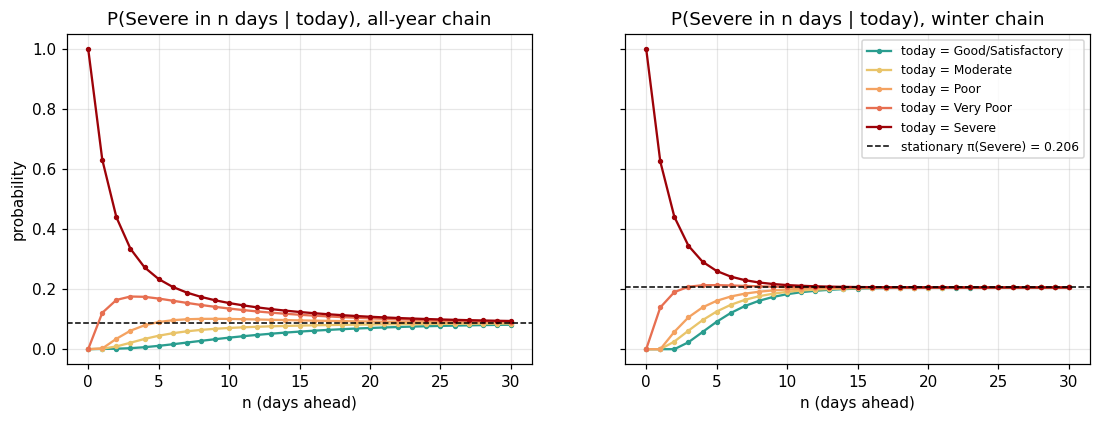

In [7]:
P_w = P_season["Winter"]
horizons = [1, 2, 3, 5, 7, 14, 30]
nstep = pd.DataFrame({f"n = {h}": np.linalg.matrix_power(P_w, h)[SEV] for h in horizons}, index=STATES).T
print("Winter chain: distribution n days after a Severe day")
display(nstep.round(3))
for h in [1, 3, 7]:
    Ph = np.linalg.matrix_power(P_w, h)
    print(f"winter, n = {h}: P(Severe on day n | today Very Poor) = {Ph[3, SEV]:.3f},  "
          f"| today Moderate) = {Ph[1, SEV]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
nn = np.arange(0, 31)
for ax, (name, M) in zip(axes, [("all-year chain", P), ("winter chain", P_w)]):
    pi_M = stationary(M)
    for i, col in zip(range(K), COLORS):
        traj = [np.linalg.matrix_power(M, h)[i, SEV] for h in nn]
        ax.plot(nn, traj, "-o", ms=2.5, color=col, label=f"today = {STATES[i]}")
    ax.axhline(pi_M[SEV], color="k", ls="--", lw=1, label=f"stationary π(Severe) = {pi_M[SEV]:.3f}")
    ax.set(title=f"P(Severe in n days | today), {name}", xlabel="n (days ahead)")
axes[0].set_ylabel("probability")
axes[1].legend(fontsize=8)
fig.savefig(FIG / "B03_n_step_severe.png")
plt.show()
RESULTS["winter_n_step_from_severe"] = nstep.to_dict("index")

**Reading.** After a Severe winter day the chance that the next day is also Severe is 0.63, two days later
0.44 and a week later 0.23. The memory fades within about **two weeks**: by then the starting state no longer
matters and every curve meets the long-run share (0.21 in winter). The second-largest eigenvalue modulus of $P$
gives the speed: the distance to equilibrium shrinks roughly like $|\lambda_2|^n$ (cell below). The all-year
chain forgets more slowly because its clean state is very sticky ($p_{11} = 0.86$).

In [8]:
for name, M in [("all-year", P), ("winter", P_w)]:
    ev = np.sort(np.abs(np.linalg.eigvals(M)))[::-1]
    print(f"{name:<9} |lambda_2| = {ev[1]:.3f}  ->  half-life of memory = {np.log(0.5) / np.log(ev[1]):.1f} days")

all-year  |lambda_2| = 0.895  ->  half-life of memory = 6.2 days
winter    |lambda_2| = 0.701  ->  half-life of memory = 2.0 days


## 4. Long-run share of days in each category (stationary distribution)

,all-year π,all-year observed,winter π,winter observed,post-monsoon π,post-monsoon observed
Good/Satisfactory,0.350,0.350,0.022,0.019,0.067,0.127
Moderate,0.181,0.181,0.092,0.084,0.065,0.100
Poor,0.124,0.124,0.125,0.121,0.116,0.125
Very Poor,0.258,0.258,0.555,0.563,0.521,0.454
Severe,0.087,0.087,0.206,0.214,0.231,0.194


mean recurrence time of Severe: all-year 1/pi = 11.5 days, winter 4.9 days


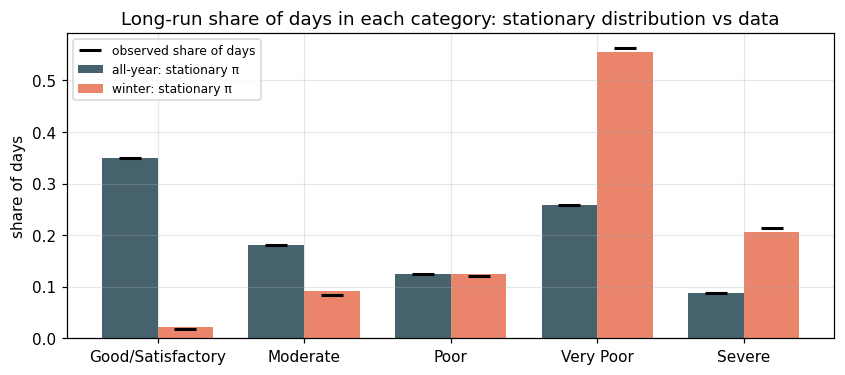

In [9]:
pi_all = stationary(P)
emp_all = study.x.value_counts(normalize=True).reindex(range(K)).to_numpy()
pi_season = {s: stationary(P_season[s]) for s in ("Winter", "Post-monsoon")}
emp_season = {s: study[study.season == s].x.value_counts(normalize=True).reindex(range(K), fill_value=0).to_numpy()
              for s in pi_season}
stat_tab = pd.DataFrame({"all-year π": pi_all, "all-year observed": emp_all,
                         "winter π": pi_season["Winter"], "winter observed": emp_season["Winter"],
                         "post-monsoon π": pi_season["Post-monsoon"],
                         "post-monsoon observed": emp_season["Post-monsoon"]}, index=STATES)
display(stat_tab.round(3))
print(f"mean recurrence time of Severe: all-year 1/pi = {1 / pi_all[SEV]:.1f} days, "
      f"winter {1 / pi_season['Winter'][SEV]:.1f} days")

fig, ax = plt.subplots(figsize=(9, 3.6))
xx = np.arange(K)
for j, (key, col) in enumerate([("all-year", "#264653"), ("winter", "#e76f51")]):
    ax.bar(xx + (j - 0.5) * 0.38, stat_tab[f"{key} π"], width=0.38, color=col, alpha=0.85, label=f"{key}: stationary π")
    ax.plot(xx + (j - 0.5) * 0.38, stat_tab[f"{key} observed"], "k_", ms=14, mew=2)
ax.plot([], [], "k_", ms=14, mew=2, label="observed share of days")
ax.set_xticks(xx, STATES)
ax.set(title="Long-run share of days in each category: stationary distribution vs data", ylabel="share of days")
ax.legend(fontsize=8)
fig.savefig(FIG / "B04_stationary.png")
plt.show()
RESULTS["stationary"] = stat_tab.to_dict("index")

**Reading.** The stationary distribution reproduces the observed shares almost exactly (all-year: 35 % G/S,
18 % Moderate, 12 % Poor, 26 % Very Poor, **8.7 % Severe**; winter: **21 % Severe**, 56 % Very Poor).
This is expected for an MLE fitted on one long path, so it is a consistency check rather than a test. The
all-year mean recurrence time of Severe, $1/\pi_5 = 11.5$ days, equals Member A's $1/\hat\lambda = 11.4$ days;
in winter a Severe day recurs every 4.9 days on average.
The post-monsoon chain does *not* match its season (π(Severe) 0.23 vs 0.19 observed). Oct–Nov is a transition
from clean October to Severe November, so it never reaches equilibrium; a stationary distribution only makes
sense for a season that is roughly stable, like winter.

## 5. How long does each kind of spell last?
Under the chain, the number of consecutive days in state $i$ is Geometric with mean $1/(1-p_{ii})$.
Observed spells are maximal runs of the same category; a missing day ends a run.

,p_ii,model mean 1/(1-p_ii),observed mean,observed sd,model sd,spells,longest,winter model mean
state,,,,,,,,
Good/Satisfactory,0.86,7.32,6.85,13.05,6.80,175,134,1.62
Moderate,0.52,2.07,2.05,1.56,1.49,303,13,1.82
Poor,0.45,1.80,1.79,1.28,1.20,237,7,1.63
Very Poor,0.72,3.57,3.46,3.12,3.03,256,15,3.89
Severe,0.63,2.71,2.68,2.67,2.15,112,17,2.67


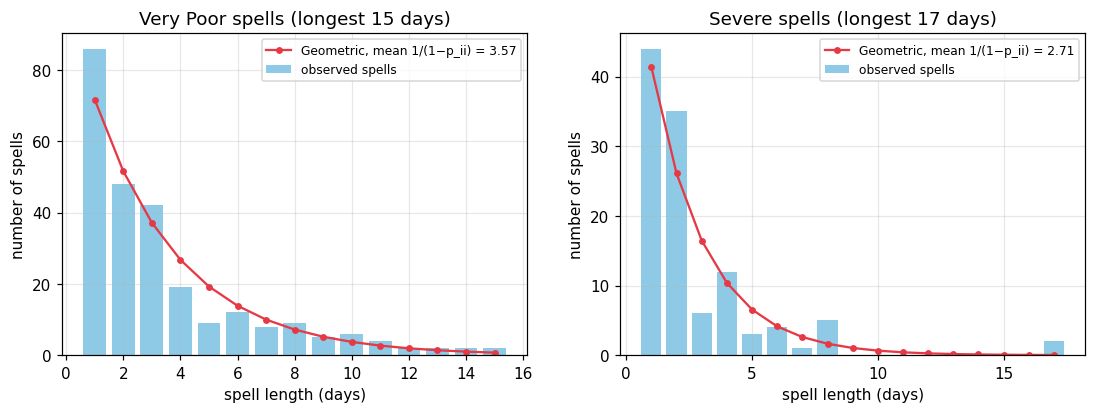

In [10]:
xs = study.x.to_numpy()
spell_rows = []
spells = {}
for i in range(K):
    L_i = run_lengths(xs, i)
    spells[i] = L_i
    spell_rows.append({"state": STATES[i], "p_ii": P[i, i], "model mean 1/(1-p_ii)": 1 / (1 - P[i, i]),
                       "observed mean": L_i.mean(), "observed sd": L_i.std(ddof=1),
                       "model sd": np.sqrt(P[i, i]) / (1 - P[i, i]), "spells": len(L_i), "longest": int(L_i.max())})
spell_tab = pd.DataFrame(spell_rows).set_index("state")
spell_wint = {i: 1 / (1 - P_w[i, i]) for i in range(K)}
spell_tab["winter model mean"] = [spell_wint[i] for i in range(K)]
display(spell_tab.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, i in zip(axes, [3, SEV]):
    L_i = spells[i]
    kk = np.arange(1, min(L_i.max(), 25) + 1)
    p = P[i, i]
    ax.bar(kk, np.bincount(L_i, minlength=kk.max() + 1)[1:kk.max() + 1], color="#8ecae6", label="observed spells")
    ax.plot(kk, len(L_i) * (1 - p) * p ** (kk - 1), "o-", ms=3.5, color="#e63946",
            label=f"Geometric, mean 1/(1−p_ii) = {1 / (1 - p):.2f}")
    ax.set(title=f"{STATES[i]} spells (longest {L_i.max()} days)", xlabel="spell length (days)", ylabel="number of spells")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.legend(fontsize=8)
fig.savefig(FIG / "B05_spell_lengths.png")
plt.show()
RESULTS["spells"] = spell_tab.reset_index().to_dict("records")

**Reading.**
* Clean spells (Good/Satisfactory) are the longest, about **7 days** on average, mostly in the monsoon.
* Very Poor spells last ≈ 3.5 days and **Severe spells ≈ 2.7 days**; Moderate and Poor spells are short
  (≈ 2 days) because these are transit states.
* Observed means agree with $1/(1-\hat p_{ii})$ for every state. The geometric shape fits Moderate, Poor and
  Very Poor well. For Severe the observed standard deviation (2.7) is above the geometric one (2.2): there are
  a few very long episodes (up to 17 days), the same heavy tail Member A found.
* Clean spells are far more variable than geometric (sd 13 vs 6.8, longest 134 days), because they come from
  two regimes: short clean breaks in winter and months-long clean periods in the monsoon. A single all-year
  $p_{ii}$ averages over seasons; in winter, for example, clean spells last only 1.6 days and Very Poor spells 3.9.

## 6. Expected time until a Severe day

**Homogeneous chains.** Mean first-passage time $m_i$ to Severe from each other state.

In [11]:
hit = pd.DataFrame({
    "all-year chain": hitting_times(P),
    "winter chain": hitting_times(P_w),
    "post-monsoon chain": hitting_times(P_season["Post-monsoon"]),
}).rename(index=dict(enumerate(STATES)))
hit.loc["Severe (recurrence 1/π)"] = [1 / pi_all[SEV], 1 / pi_season["Winter"][SEV], 1 / pi_season["Post-monsoon"][SEV]]
print("mean number of days until the next Severe day")
display(hit.round(1))
RESULTS["hitting_times"] = hit.to_dict("index")

mean number of days until the next Severe day


,all-year chain,winter chain,post-monsoon chain
Good/Satisfactory,53.0,15.6,23.4
Moderate,46.5,14.4,18.6
Poor,39.6,13.2,13.5
Very Poor,27.5,10.2,9.3
Severe (recurrence 1/π),11.5,4.9,4.3


In winter, a Severe day comes on average about **10 days** after a Very Poor day and about 2 weeks after a
cleaner day. The all-year numbers (28–53 days) are averages over a calendar that the homogeneous chain
ignores: a clean day in July is really 3–4 months away from the next Severe day.

**Time-varying chain.** To answer the question for a real calendar date we let the transition matrix change
by **month**, $P_{m(n)}$ (rows with fewer than 10 transitions in a month fall back to the season's row).
Starting on 1 October, the distribution of the date of the first Severe day comes from making Severe absorbing
and iterating $v_{n+1} = v_n P_{m(n)}$. This is compared with the actual first Severe day of each season.

,state on 1 Oct,first Severe day,days after 1 Oct
season,,,
2016/17,Poor,2016-10-27,26
2017/18,Good,2017-11-07,37
2018/19,Moderate,2018-10-30,29
2019/20,Good,2019-10-28,27
2020/21,Moderate,2020-10-31,30
2021/22,Satisfactory,2021-11-05,35
2022/23,Poor,2022-10-31,30
2023/24,Moderate,2023-11-02,32
2024/25,Poor,2024-11-01,31


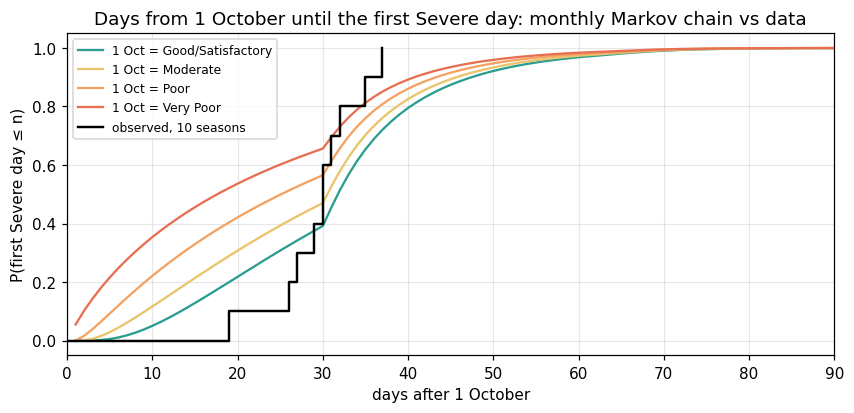

,mean days,median days,P(by 31 Oct),P(by 15 Nov),P(by 31 Dec)
Good/Satisfactory,31.765,32.0,0.392,0.874,1.0
Moderate,28.993,31.0,0.470,0.893,1.0
Poor,25.269,26.0,0.565,0.915,1.0
Very Poor,21.037,18.0,0.656,0.935,1.0


observed: mean 29.6 days, median 30, range 19–37


In [12]:
C_month = {m: transition_counts(study[study.month == m]) for m in range(1, 13)}
P_month = {}
for m in range(1, 13):
    M = C_month[m].copy()
    fb = C_season[SEASON_OF[m]]
    for i in range(K):
        if M[i].sum() < 10:
            M[i] = fb[i] if fb[i].sum() >= 10 else C[i]
    P_month[m] = row_normalise(M)


def first_passage_cdf(start_state, dates, P_by_month, target=SEV):
    """P(first visit to `target` is on or before each date), starting the day before dates[0]."""
    v = np.zeros(K)
    v[start_state] = 1.0
    cdf = []
    for d in dates:
        v = v @ P_by_month[d.month]
        v[target] = 0.0                                  # absorbed mass = already hit
        cdf.append(1 - v.sum())
    return np.array(cdf)


season_dates = pd.date_range("2025-10-02", "2026-03-31")  # day 1 = 2 Oct when starting on 1 Oct
obs_first = []
for y in range(2016, 2026):
    s = df.loc[f"{y}-10-01":f"{y + 1}-03-31"]
    first = s.index[s.aqi_category == "Severe"]
    obs_first.append({"season": f"{y}/{str(y + 1)[2:]}", "state on 1 Oct": s.aqi_category.iloc[0],
                      "first Severe day": first[0].date(), "days after 1 Oct": (first[0] - s.index[0]).days})
obs_first = pd.DataFrame(obs_first).set_index("season")
display(obs_first)

fp_rows = {}
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, col in zip(range(4), COLORS):
    cdf = first_passage_cdf(i, season_dates, P_month)
    mean_days = float(np.sum(1 - cdf)) + 1                   # E[T] = sum_{n>=0} P(T > n)
    med = int(np.searchsorted(cdf, 0.5)) + 1
    fp_rows[STATES[i]] = {"mean days": mean_days, "median days": med,
                          "P(by 31 Oct)": cdf[29], "P(by 15 Nov)": cdf[44], "P(by 31 Dec)": cdf[90]}
    ax.plot(np.arange(1, len(cdf) + 1), cdf, color=col, label=f"1 Oct = {STATES[i]}")
ecdf_x = np.sort(obs_first["days after 1 Oct"].to_numpy())
ax.step(np.r_[0, ecdf_x], np.r_[0, np.arange(1, len(ecdf_x) + 1) / len(ecdf_x)], where="post", color="k", lw=1.6,
        label="observed, 10 seasons")
ax.set(xlim=(0, 90), title="Days from 1 October until the first Severe day: monthly Markov chain vs data",
       xlabel="days after 1 October", ylabel="P(first Severe day ≤ n)")
ax.legend(fontsize=8)
fig.savefig(FIG / "B06_first_severe_day.png")
plt.show()
fp_tab = pd.DataFrame(fp_rows).T
display(fp_tab.round(3))
print(f"observed: mean {obs_first['days after 1 Oct'].mean():.1f} days, "
      f"median {obs_first['days after 1 Oct'].median():.0f}, range {ecdf_x.min()}–{ecdf_x.max()}")
RESULTS["first_severe_after_oct1"] = {"model": fp_tab.to_dict("index"),
                                      "observed": obs_first.reset_index().to_dict("records")}
RESULTS["P_month"] = {str(m): P_month[m].tolist() for m in range(1, 13)}

**Reading.** The monthly chain predicts the first Severe day of the winter about **3–4.5 weeks after
1 October**: on average 21 days from a Very Poor start, 29 days from Moderate (the typical 1 October state) and
32 days from Good/Satisfactory. The chance of a Severe day by 15 November is 87–94 %, and by the end of December
it is certain. In the 10 observed seasons the first Severe day came 19–37 days after 1 October (mean 29.6,
median 30), so the model gets the **typical date right**. The observed dates are however much more tightly
bunched than the model says: the chain gives a 20–50 % chance of a Severe day in the first three weeks of
October, but it never happened in ten years. The reason is that the October matrix is constant within the
month, so the few Severe days of late October (around Diwali and the peak of crop burning) are spread over the
whole month. A matrix that changes week by week, or depends on weather and fire counts, would fix this.

## 7. Is yesterday enough? Testing the order of the chain

* **Order 0 vs 1:** is today independent of yesterday?
* **Order 1 vs 2:** given yesterday, does the day before yesterday still matter?

A test that pools all seasons can find spurious "extra memory": if the chain changes with the season, the
day before yesterday carries information about *which season it is*. So the test is done both pooled and
within each season (the stratified $G^2$ adds up the per-season statistics and degrees of freedom).

In [13]:
order_rows = {}
for name, d in [("pooled 2016–2025", study)] + [(s, study[study.season == s]) for s in SEASONS]:
    g01, df01 = g2_independence(transition_counts(d))
    g12, df12, p12 = g2_order(triple_counts(d))
    order_rows[name] = {"G2 order 0 vs 1": g01, "df 0v1": df01, "p 0v1": stats.chi2.sf(g01, df01),
                        "G2 order 1 vs 2": g12, "df 1v2": df12, "p 1v2": p12}
strat = [g2_order(triple_counts(study[study.season == s])) for s in SEASONS]
Gs, dfs = sum(r[0] for r in strat), sum(r[1] for r in strat)
order_rows["stratified by season"] = {"G2 order 1 vs 2": Gs, "df 1v2": dfs, "p 1v2": stats.chi2.sf(Gs, dfs)}
strat_m = [g2_order(triple_counts(study[study.month == m])) for m in range(1, 13)]
Gm, dfm = sum(r[0] for r in strat_m), sum(r[1] for r in strat_m)
order_rows["stratified by month"] = {"G2 order 1 vs 2": Gm, "df 1v2": dfm, "p 1v2": stats.chi2.sf(Gm, dfm)}
order_tab = pd.DataFrame(order_rows).T
with pd.option_context("display.float_format", "{:.3g}".format):
    display(order_tab)
RESULTS["order_test"] = order_tab.reset_index(names="data").to_dict("records")

,G2 order 0 vs 1,df 0v1,p 0v1,G2 order 1 vs 2,df 1v2,p 1v2
pooled 2016–2025,4.64e+03,16,0,186,72,5.29e-12
Winter,521,16,1.03e-100,39.8,45,0.693
Summer,540,16,1.17e-104,82.1,54,0.00821
Monsoon,394,9,2.22e-79,47.6,26,0.00604
Post-monsoon,746,16,2.57e-148,54.5,42,0.0934
stratified by season,NaN,NaN,NaN,224,167,0.00217
stratified by month,NaN,NaN,NaN,382,303,0.00144


### Information criteria (orders 0, 1, 2)
All three models are fitted to the same days (those with two valid previous days).
Free parameters: $(K-1)$, $K(K-1)$ and $K^2(K-1)$.

In [14]:
N3 = triple_counts(study)
N2, N1 = N3.sum(axis=0), N3.sum(axis=(0, 1))
n_obs = N3.sum()


def cond_loglik(N):
    """sum n * log(n / row total) over the last axis."""
    S = np.broadcast_to(N.sum(axis=-1, keepdims=True), N.shape)
    m = N > 0
    return float(np.sum(N[m] * np.log(N[m] / S[m])))


ic = pd.DataFrame({"order": [0, 1, 2], "params": [K - 1, K * (K - 1), K * K * (K - 1)],
                   "loglik": [cond_loglik(N1), cond_loglik(N2), cond_loglik(N3)]}).set_index("order")
ic["AIC"] = 2 * ic.params - 2 * ic.loglik
ic["BIC"] = np.log(n_obs) * ic.params - 2 * ic.loglik
display(ic.round(1))
RESULTS["information_criteria"] = ic.reset_index().to_dict("records")

,params,loglik,AIC,BIC
order,,,,
0,4,-5036.9,10081.7,10106.2
1,20,-2740.5,5520.9,5643.3
2,100,-2647.6,5495.1,6107.1


### The question that matters most: does a second Severe day make a third more likely?

In [15]:
mem_rows = []
for name, d in [("all-year", study), ("Winter", study[study.season == "Winter"]),
                ("Post-monsoon", study[study.season == "Post-monsoon"])]:
    N = triple_counts(d)
    a, b = N[SEV, SEV, SEV], N[SEV, SEV].sum()             # (S, S) -> S
    c_, e = N[:SEV, SEV, SEV].sum(), N[:SEV, SEV].sum()    # (not S, S) -> S
    tab = np.array([[a, b - a], [c_, e - c_]])
    mem_rows.append({"data": name, "P(S | S,S)": a / b, "n (S,S)": int(b), "P(S | not S,S)": c_ / e,
                     "n (not S,S)": int(e), "Fisher p": stats.fisher_exact(tab)[1]})
mem = pd.DataFrame(mem_rows).set_index("data")
display(mem.round(3))
RESULTS["severe_memory"] = mem.reset_index().to_dict("records")

,"P(S | S,S)","n (S,S)","P(S | not S,S)","n (not S,S)",Fisher p
data,,,,,
all-year,0.645,186,0.606,109,0.533
Winter,0.623,114,0.618,68,1.000
Post-monsoon,0.681,72,0.632,38,0.673


**Reading.**
* Yesterday matters enormously (order 0 vs 1: G² ≈ 4600, p ≈ 0): the days are not independent.
* **Pooled over the year** the first-order chain is rejected (G² = 186, df = 72, p ≈ 10⁻¹²; G²/df = 2.6), and
  AIC slightly prefers order 2. Most of this comes from mixing seasons. **Within winter** (p = 0.69) and
  **post-monsoon** (p = 0.09), the seasons that contain almost all Severe days, yesterday alone is enough.
  A weaker second-order effect remains in summer and the monsoon (p ≈ 0.007; stratified over all seasons
  G²/df = 1.3, p = 0.002), where pollution trends steadily within the season. BIC, which punishes the
  100-parameter second-order model, clearly picks **order 1**.
* For Severe days specifically: $P(S \mid S,S) = 0.65$ vs $P(S \mid \text{not }S, S) = 0.61$ (Fisher p = 0.53);
  in winter the two are equal (0.62 vs 0.62). A second Severe day does not make a third more likely, so the
  long Severe episodes are not caused by two-day memory.
* **Conclusion:** a first-order chain **with seasonal (or monthly) transition matrices** is adequate. The
  out-of-sample check below confirms this.

## 8. Out-of-sample check
Same split as the Poisson part: fit on **2016–2022**, then predict each day of **2023 – Sep 2026** from the
state of the previous day(s). A pseudo-count of 0.1 per cell avoids zero probabilities. Scores:
* mean log predictive probability of the observed category (higher is better);
* accuracy of the most likely category;
* Brier score of P(Severe tomorrow) (lower is better), which can also be computed for Member A's monthly
  NHPP, where P(Severe on a day) = $\hat\lambda_m$ regardless of yesterday.

In [16]:
ALPHA = 0.1
train = study.loc[:TRAIN_END]
test = pd.concat([study.loc[TRAIN_END:].iloc[1:], holdout])


def fit_P(d):
    return row_normalise(transition_counts(d) + ALPHA)


P_tr = fit_P(train)
P_tr_s = {s: fit_P(train[train.season == s]) for s in SEASONS}
N3_tr_s = {s: triple_counts(train[train.season == s]) + ALPHA for s in SEASONS}
f0_tr = {m: np.bincount(train[train.month == m].x.dropna().astype(int), minlength=K) + ALPHA for m in range(1, 13)}
f0_tr = {m: v / v.sum() for m, v in f0_tr.items()}
lam_m_A = {int(m): v for m, v in json.loads((RES / "A02_poisson_results.json").read_text())["train_params"]["lambda_m"].items()}

tt = test.dropna(subset=["prev", "x"])
x_t, y_t = tt.x.astype(int).to_numpy(), tt.prev.astype(int).to_numpy()
z_ok = tt.prev2.notna().to_numpy()
z_t = np.nan_to_num(tt.prev2.to_numpy()).astype(int)
seas_t, mon_t = tt.season.to_numpy(), tt.month.to_numpy()

pred = {
    "Order 0, monthly frequencies": np.array([f0_tr[m] for m in mon_t]),
    "Order 1, all-year": P_tr[y_t],
    "Order 1, seasonal": np.array([P_tr_s[s][j] for s, j in zip(seas_t, y_t)]),
    "Order 2, seasonal": np.array([N3_tr_s[s][i, j] / N3_tr_s[s][i, j].sum() if ok else P_tr_s[s][j]
                                   for s, i, j, ok in zip(seas_t, z_t, y_t, z_ok)]),
}
is_sev = (x_t == SEV).astype(float)
oos_rows = {}
for name, pr in pred.items():
    oos_rows[name] = {"mean log score": np.log(pr[np.arange(len(x_t)), x_t]).mean(),
                      "accuracy": (pr.argmax(axis=1) == x_t).mean(),
                      "Brier P(Severe)": np.mean((pr[:, SEV] - is_sev) ** 2)}
p_nhpp = np.array([lam_m_A[m] for m in mon_t])
oos_rows["Member A monthly NHPP"] = {"mean log score": np.nan, "accuracy": np.nan,
                                     "Brier P(Severe)": np.mean((p_nhpp - is_sev) ** 2)}
oos = pd.DataFrame(oos_rows).T
print(f"test transitions: {len(x_t)}, Severe days among them: {int(is_sev.sum())}")
display(oos.round(4))
RESULTS["oos"] = oos.reset_index(names="model").to_dict("records")
RESULTS["train_P"] = P_tr.tolist()
RESULTS["train_P_season"] = {s: P_tr_s[s].tolist() for s in SEASONS}

test transitions: 1333, Severe days among them: 120


,mean log score,accuracy,Brier P(Severe)
"Order 0, monthly frequencies",-1.0422,0.5514,0.0598
"Order 1, all-year",-0.9032,0.6467,0.0521
"Order 1, seasonal",-0.8528,0.6459,0.0508
"Order 2, seasonal",-0.8979,0.6302,0.0509
Member A monthly NHPP,NaN,NaN,0.0598


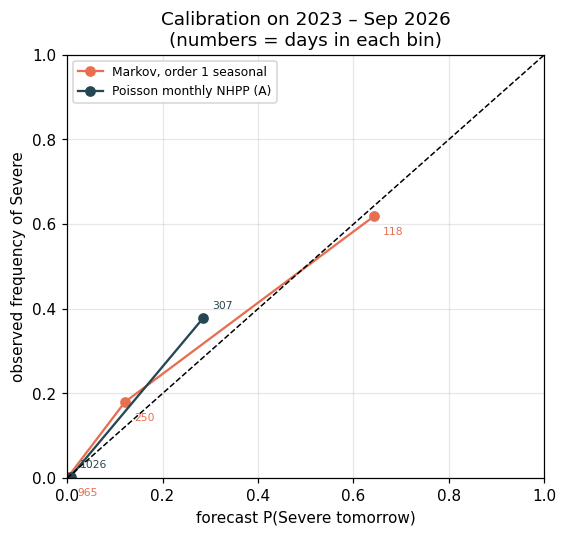

In [17]:
bins = np.array([0, 0.05, 0.2, 0.45, 1.0])
fig, ax = plt.subplots(figsize=(5.6, 5))
for name, p_, col in [("Markov, order 1 seasonal", pred["Order 1, seasonal"][:, SEV], "#e76f51"),
                      ("Poisson monthly NHPP (A)", p_nhpp, "#264653")]:
    b = np.digitize(p_, bins[1:-1])
    g = pd.DataFrame({"b": b, "p": p_, "y": is_sev}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    ax.plot(g.p, g.y, "o-", color=col, label=name)
    for _, r in g.iterrows():
        ax.annotate(f"{int(r.n)}", (r.p, r.y), textcoords="offset points", xytext=(6, -12 if col == "#e76f51" else 6),
                    fontsize=7, color=col)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="forecast P(Severe tomorrow)", ylabel="observed frequency of Severe",
       title="Calibration on 2023 – Sep 2026\n(numbers = days in each bin)")
ax.legend(fontsize=8, loc="upper left")
fig.savefig(FIG / "B07_calibration.png")
plt.show()

**Reading.**
* Knowing yesterday's state improves every score: log score −1.04 → −0.85, accuracy 55 % → 65 %.
* The **seasonal first-order chain is best**. The second-order seasonal chain is *worse* out of sample
  (its many extra parameters overfit), which confirms the order test.
* For predicting a Severe day, the Markov chain's Brier score (0.051) beats the Poisson NHPP (0.060).
  The NHPP gives every January day the same ≈ 0.3 chance; the chain gives about 0.6 after a Severe day and
  almost 0 after a Moderate one, and these forecasts are roughly calibrated (B07: about 62 % of days forecast
  at ≈ 0.64 were Severe). The Poisson model counts
  Severe days well, and the Markov chain predicts *which* days.

## Conclusions (Member B)
1. **Model.** Daily AQI category at R K Puram (5 states, Good + Satisfactory merged) as a first-order Markov
   chain; 3394 usable transitions in 2016–2025, chain broken at missing days.
2. **Persistence.** The matrix is strongly diagonal and moves are almost always one category at a time.
   $\hat p_{\text{Severe,Severe}} = 0.631$ (95 % CI 0.58–0.68), consistent with Member A's 0.627.
3. **Seasons.** Winter and summer chains differ strongly (homogeneity p ≈ 10⁻⁴⁴): in winter the chain drifts
   towards Very Poor/Severe, and in summer towards Moderate. Severe persistence is the same in winter and
   post-monsoon (≈ 0.63–0.66).
4. **Over several days.** After a Severe winter day: P(Severe) = 0.63 tomorrow, 0.44 in 2 days, 0.23 in a
   week; memory is gone after about two weeks.
5. **Long run.** Stationary shares match the data: 8.7 % Severe all year (one every 11.5 days), 21 % in winter.
6. **Spells.** Mean lengths: clean 7.3 days, Very Poor 3.6, Severe 2.7, Moderate/Poor ≈ 2; geometric except for
   a few long Severe episodes and the very long monsoon clean spells.
7. **Time to Severe.** In winter ≈ 10 days from Very Poor and ≈ 2 weeks from cleaner states. With monthly
   matrices the first Severe day of the season is predicted ≈ 4 weeks after 1 October (29 days from a Moderate
   start), matching the mean of the 10 observed seasons (29.6 days); the model is too spread out, because it
   allows early-October Severe days that did not occur.
8. **Order.** Yesterday alone is enough within the polluted seasons (winter p = 0.69, post-monsoon p = 0.09);
   the strong pooled rejection is mostly caused by mixing seasons, and a weak second-order effect remains only
   in summer and the monsoon. BIC and out-of-sample scores both choose a seasonal first-order chain.

**Limitations.** One station; category boundaries throw away the size of PM2.5 within a class; seasonal rows
with few transitions (summer/monsoon Severe, winter Good/Satisfactory) are uncertain; 6 % missing and 5 %
interpolated days; year-to-year differences (e.g. the bad winter of 2023) are not modelled; no weather covariates.

**Extensions.** Transition probabilities depending on weather (multinomial logistic regression); a hidden
Markov model with latent "meteorological regimes"; a continuous-state model (e.g. autoregression on log PM2.5).

## 9. Save results and parameters for the team

In [18]:
def to_py(o):
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [to_py(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 6)
    if isinstance(o, np.bool_):
        return bool(o)
    return o

(RES / "B01_markov_results.json").write_text(json.dumps(to_py(RESULTS), indent=2, default=str))
params = {"states": STATES, "fit_period": "2016-01-01..2025-12-31", "time_step": "day",
          "P_all_year": P, "P_by_season": P_season, "P_by_month": {str(m): P_month[m] for m in range(1, 13)},
          "season_months": SEASON_OF, "stationary_all_year": pi_all,
          "p_severe_severe": p_ss, "train_period": "2016-01-01..2022-12-31",
          "train_P_by_season": P_tr_s, "train_pseudocount": ALPHA,
          "note": "rows of P_by_month with < 10 transitions copy the season row; summer/monsoon Severe rows are "
                  "unreliable (3 and 0 Severe days)"}
(RES / "markov_params.json").write_text(json.dumps(to_py(params), indent=2))
print("saved results/B01_markov_results.json and results/markov_params.json")

saved results/B01_markov_results.json and results/markov_params.json
